<a href="https://colab.research.google.com/github/leovarconrenno/Estacao-de-Reabastecimento-de-Hidrogenio---SCADA-Core/blob/main/etapa-03-arvores/Aula%2028%20-%20Apresenta%C3%A7%C3%A3o%20e%20Simula%C3%A7%C3%A3o%20do%20M%C3%B3dulo%203%20-%20code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 28 - Notebook: Simulação Integrada do Módulo 3 (`SCADACoreModulo3`)

Este notebook integra **de forma executável** as estruturas de **Árvores (Aulas 19 a 27)** em um simulador único da Estação de Reabastecimento de Hidrogênio (`SCADA-Core`):
1. **RSTP + MST (Aulas 19 e 23):** Eleição de *Root Bridge* por prioridade/MAC e verificação de caminho após corte do *backbone*;
2. **Huffman Dinâmico (Aula 20):** Construção da árvore de prefixos para `[PT-101, TT-101, AT-101/301, TT-201, ESD-100]`;
3. **BDT + Behavior Tree (Aulas 21 e 25):** Orquestração reativa com preempção imediata via `Fallback`/`Sequence`;
4. **Historiador AVL (Aula 21) + KD-Tree 4D (Aula 26) + Árvore CART (Aula 27):** Indexação temporal, escore de anomalia e diagnóstico automático de causa raiz.

In [1]:
import heapq
from enum import Enum
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
np.random.seed(42)
print("Módulos base carregados para o SCADACoreModulo3.")

Módulos base carregados para o SCADACoreModulo3.


### 1. Subsistemas Integrados: RSTP, Huffman, Behavior Tree + BDT, AVL, KD-Tree e CART

In [2]:
# --- 1.1 RSTP (Aulas 19 e 23) ---
def verificar_rede_rstp(corte_backbone: bool = False):
    G = nx.Graph()
    switches = {"SW-SCADA": 4096, "SW-S100": 8192, "SW-S200": 32768, "SW-S300": 32768, "SW-SIS": 32768}
    for s, p in switches.items():
        G.add_node(s, prio=p)
    for u, v, w in [
        ("SW-SCADA", "SW-S100", 2000), ("SW-SCADA", "SW-SIS", 20000),
        ("SW-S100", "SW-S200", 20000), ("SW-S200", "SW-S300", 20000), ("SW-S300", "SW-SIS", 20000),
        ("SW-S100", "SW-SIS", 200000)
    ]:
        G.add_edge(u, v, cost=w)
    if corte_backbone:
        G.remove_edge("SW-SCADA", "SW-S100")
    root = min(G.nodes, key=lambda n: G.nodes[n]["prio"])
    dist = nx.single_source_dijkstra_path_length(G, root, weight="cost")
    T = nx.minimum_spanning_tree(G, weight="cost")
    return nx.is_connected(T) and T.number_of_edges() == G.number_of_nodes() - 1, root, dist["SW-S100"]

# --- 1.2 Huffman Dinamico (Aula 20) ---
PROBS_H2 = {"00000": 0.900, "00010": 0.050, "10000": 0.025, "01000": 0.015, "00100": 0.009, "00001": 0.001}
def gerar_huffman(probs):
    heap = [[p, [sym, ""]] for sym, p in probs.items()]
    heapq.heapify(heap)
    while len(heap) > 1:
        lo = heapq.heappop(heap)
        hi = heapq.heappop(heap)
        for pair in hi[1:]: pair[1] = "0" + pair[1]
        for pair in lo[1:]: pair[1] = "1" + pair[1]
        heapq.heappush(heap, [lo[0] + hi[0]] + hi[1:] + lo[1:])
    return dict(sorted(heapq.heappop(heap)[1:], key=lambda p: len(p[1])))

HUFFMAN_CODES = gerar_huffman(PROBS_H2)

def codificar_telemetria_huffman(pt101, tt101, at_max, tt201, esd100):
    bits = f"{int(pt101>400)}{int(tt101>85)}{int(at_max>25)}{int(tt201>-33)}{int(esd100==1)}"
    return HUFFMAN_CODES.get(bits, "11111"), bits

# --- 1.3 BDT + Behavior Tree (Aulas 21 e 25) ---
class BTStatus(Enum):
    SUCCESS = "SUCCESS"; FAILURE = "FAILURE"; RUNNING = "RUNNING"

class BTNode:
    def tick(self, bb): raise NotImplementedError

class Sequence(BTNode):
    def __init__(self, children): self.children = children
    def tick(self, bb):
        for c in self.children:
            s = c.tick(bb)
            if s != BTStatus.SUCCESS: return s
        return BTStatus.SUCCESS

class Fallback(BTNode):
    def __init__(self, children): self.children = children
    def tick(self, bb):
        for c in self.children:
            s = c.tick(bb)
            if s != BTStatus.FAILURE: return s
        return BTStatus.FAILURE

class Cond(BTNode):
    def __init__(self, fn): self.fn = fn
    def tick(self, bb): return BTStatus.SUCCESS if self.fn(bb) else BTStatus.FAILURE

class Act(BTNode):
    def __init__(self, fn): self.fn = fn
    def tick(self, bb): return self.fn(bb)

def bdt_sis_ok(bb) -> bool:
    return not (bb["esd100"] == 1 or bb["pt101"] > 400.0 or bb["tt101"] > 85.0 or bb["at_max"] > 25.0)

def act_abastecer(bb):
    if bb["pt301"] >= 700.0:
        bb["xv301"] = 0; bb["status"] = "CONCLUIDO"
        return BTStatus.SUCCESS
    bb["xv301"] = 1; bb["status"] = "ABASTECENDO"
    bb["pt301"] = min(700.0, bb["pt301"] + 55.0)
    return BTStatus.RUNNING

def act_trip_sis(bb):
    bb["xv301"] = 0; bb["alarme"] = 1; bb["status"] = "TRIP_SIS"
    return BTStatus.SUCCESS

# --- 1.4 AVL + KD-Tree 4D + CART (Aulas 21, 26 e 27) ---
class AVLNode:
    def __init__(self, k, v): self.k, self.v, self.l, self.r, self.h = k, v, None, None, 1

class AVLHistoriador:
    def __init__(self): self.root = None
    def _h(self, n): return n.h if n else 0
    def _rot_r(self, y):
        x = y.l; y.l = x.r; x.r = y
        y.h = 1 + max(self._h(y.l), self._h(y.r)); x.h = 1 + max(self._h(x.l), self._h(x.r))
        return x
    def _rot_l(self, x):
        y = x.r; x.r = y.l; y.l = x
        x.h = 1 + max(self._h(x.l), self._h(x.r)); y.h = 1 + max(self._h(y.l), self._h(y.r))
        return y
    def _ins(self, n, k, v):
        if not n: return AVLNode(k, v)
        if k < n.k: n.l = self._ins(n.l, k, v)
        else: n.r = self._ins(n.r, k, v)
        n.h = 1 + max(self._h(n.l), self._h(n.r))
        bf = self._h(n.r) - self._h(n.l)
        if bf < -1 and k < n.l.k: return self._rot_r(n)
        if bf > 1 and k >= n.r.k: return self._rot_l(n)
        if bf < -1 and k >= n.l.k: n.l = self._rot_l(n.l); return self._rot_r(n)
        if bf > 1 and k < n.r.k: n.r = self._rot_r(n.r); return self._rot_l(n)
        return n
    def inserir(self, k, v): self.root = self._ins(self.root, k, v)
    def range_query(self, k1, k2):
        res = []
        def _in(n):
            if not n: return
            if n.k > k1: _in(n.l)
            if k1 <= n.k <= k2: res.append(n.v)
            if n.k < k2: _in(n.r)
        _in(self.root); return res

class KDTreeSimple:
    def __init__(self, pts):
        self.k = pts.shape[1]
        self.root = self._build(list(pts), 0)
    def _build(self, pts, d):
        if not pts: return None
        ax = d % self.k
        pts.sort(key=lambda p: p[ax])
        m = len(pts) // 2
        return (pts[m], ax, self._build(pts[:m], d+1), self._build(pts[m+1:], d+1))
    def dist_nn(self, q):
        best = [float("inf")]
        def _s(n):
            if not n: return
            pt, ax, l, r = n
            d = float(np.linalg.norm(q - pt))
            if d < best[0]: best[0] = d
            diff = q[ax] - pt[ax]
            prim, sec = (l, r) if diff <= 0 else (r, l)
            _s(prim)
            if abs(diff) < best[0]: _s(sec)
        _s(self.root); return best[0]

# Treinar CART simples em dados nominais e de falha
ESCALAS_4D = np.array([400.0, 85.0, 25.0, 60.0])
baseline_nom = np.column_stack([
    np.random.normal(340, 10, 300), np.random.normal(26, 4, 300),
    np.abs(np.random.normal(2, 0.8, 300)), np.random.normal(-40, 2, 300)
])
kdtree_nom = KDTreeSimple(baseline_nom / ESCALAS_4D)

class CARTNode:
    def __init__(self, feat=None, th=None, l=None, r=None, val=None):
        self.feat, self.th, self.l, self.r, self.val = feat, th, l, r, val

def treinar_cart():
    X = np.vstack([
        baseline_nom,
        np.column_stack([np.random.normal(350,10,100), np.random.normal(76,5,100), np.abs(np.random.normal(2,1,100)), np.random.normal(-10,5,100)]),
        np.column_stack([np.random.normal(415,10,100), np.random.normal(35,5,100), np.abs(np.random.normal(2,1,100)), np.random.normal(-38,2,100)]),
        np.column_stack([np.random.normal(330,15,100), np.random.normal(28,6,100), np.random.uniform(18,45,100), np.random.normal(-38,2,100)]),
    ])
    y = np.array(["Nominal"]*300 + ["Falha_Chiller_Termica"]*100 + ["Sobrepressao_Cascata"]*100 + ["Vazamento_H2"]*100)
    def gini(yy):
        _, c = np.unique(yy, return_counts=True); p = c/len(yy); return 1.0 - np.sum(p**2)
    def build(XX, yy, d=0):
        vals, cnts = np.unique(yy, return_counts=True)
        maj = vals[np.argmax(cnts)]
        if d >= 3 or len(vals) == 1: return CARTNode(val=maj)
        g0 = gini(yy); best_g, bf, bt = 0.0, None, None
        for f in range(XX.shape[1]):
            u = np.unique(XX[:, f])
            for th in (u[:-1] + u[1:]) / 2.0:
                m = XX[:, f] <= th
                if m.sum() == 0 or (~m).sum() == 0: continue
                gain = g0 - (m.mean()*gini(yy[m]) + (~m).mean()*gini(yy[~m]))
                if gain > best_g: best_g, bf, bt = gain, f, float(th)
        if bf is None: return CARTNode(val=maj)
        m = XX[:, bf] <= bt
        return CARTNode(feat=bf, th=bt, l=build(XX[m], yy[m], d+1), r=build(XX[~m], yy[~m], d+1))
    return build(X, y)

cart_model = treinar_cart()
def diagnosticar_cart(x_vec):
    n = cart_model
    while n.val is None:
        n = n.l if x_vec[n.feat] <= n.th else n.r
    return str(n.val)

### 2. Classe `SCADACoreModulo3` e Execução dos Cenários de Estresse

In [3]:
class SCADACoreModulo3:
    def simular_ciclo(self, nome: str, corte_fibra: bool = False, tick_vazamento: int = None):
        rede_ok, root_sw, custo_s100 = verificar_rede_rstp(corte_backbone=corte_fibra)
        bt = Fallback([Sequence([Cond(bdt_sis_ok), Act(act_abastecer)]), Act(act_trip_sis)])
        avl = AVLHistoriador()
        bb = {"pt301": 50.0, "tt201": -40.0, "pt101": 340.0, "tt101": 26.0, "at_max": 2.0, "esd100": 0, "xv301": 0, "alarme": 0, "status": "INICIO"}
        bits_fixos, bits_huff = 0, 0
        logs = []

        for tick in range(1, 16):
            if tick_vazamento is not None and tick >= tick_vazamento:
                bb["at_max"] = 34.0  # Vazamento > 25% LIE

            cod, _ = codificar_telemetria_huffman(bb["pt101"], bb["tt101"], bb["at_max"], bb["tt201"], bb["esd100"])
            bits_fixos += 5; bits_huff += len(cod)

            bt.tick(bb)
            x4d = np.array([bb["pt101"], bb["tt101"], bb["at_max"], bb["tt201"]])
            dist_kd = kdtree_nom.dist_nn(x4d / ESCALAS_4D)
            diag_cart = diagnosticar_cart(x4d)

            banco = "TK-101 (LP)" if bb["pt301"] < 350 else ("TK-102 (MP)" if bb["pt301"] < 650 else "TK-103 (HP)")
            reg = {
                "Tick": tick, "Rede_RSTP": rede_ok, "PT_301_bar": bb["pt301"],
                "AT_301_LIE": bb["at_max"], "Banco_XV104": banco, "XV_301": bb["xv301"],
                "Dist_KDTree": round(dist_kd, 3), "Status": bb["status"], "Diagnostico_CART": diag_cart
            }
            avl.inserir(1772450000000 + tick * 100, reg)
            logs.append(reg)
            if bb["status"] in ("TRIP_SIS", "CONCLUIDO"):
                break

        economia = (1.0 - bits_huff / bits_fixos) * 100.0
        rec_avl = avl.range_query(1772450000000, 1772450002000)
        print(f"=== {nome} ===")
        print(f"  RSTP Root={root_sw} | Custo SW-S100={custo_s100} | Rede OK={rede_ok} | Huffman=-{economia:.1f}% banda")
        print(f"  Historiador AVL: altura={avl.root.h}, registros recuperados={len(rec_avl)}")
        return pd.DataFrame(logs)

scada = SCADACoreModulo3()
df_a = scada.simular_ciclo("Cenário A (Nominal 700 bar)")
df_b = scada.simular_ciclo("Cenário B (Corte Fibra + Vazamento AT-301)", corte_fibra=True, tick_vazamento=8)

display(df_a.tail(4))
display(df_b.tail(4))

=== Cenário A (Nominal 700 bar) ===
  RSTP Root=SW-SCADA | Custo SW-S100=2000 | Rede OK=True | Huffman=-80.0% banda
  Historiador AVL: altura=4, registros recuperados=13
=== Cenário B (Corte Fibra + Vazamento AT-301) ===
  RSTP Root=SW-SCADA | Custo SW-S100=80000 | Rede OK=True | Huffman=-70.0% banda
  Historiador AVL: altura=4, registros recuperados=8


,Tick,Rede_RSTP,PT_301_bar,AT_301_LIE,Banco_XV104,XV_301,Dist_KDTree,Status,Diagnostico_CART
9,10,True,600.0,2.0,TK-102 (MP),1,0.006,ABASTECENDO,Nominal
10,11,True,655.0,2.0,TK-103 (HP),1,0.006,ABASTECENDO,Nominal
11,12,True,700.0,2.0,TK-103 (HP),1,0.006,ABASTECENDO,Nominal
12,13,True,700.0,2.0,TK-103 (HP),0,0.006,CONCLUIDO,Nominal


,Tick,Rede_RSTP,PT_301_bar,AT_301_LIE,Banco_XV104,XV_301,Dist_KDTree,Status,Diagnostico_CART
4,5,True,325.0,2.0,TK-101 (LP),1,0.006,ABASTECENDO,Nominal
5,6,True,380.0,2.0,TK-102 (MP),1,0.006,ABASTECENDO,Nominal
6,7,True,435.0,2.0,TK-102 (MP),1,0.006,ABASTECENDO,Nominal
7,8,True,435.0,34.0,TK-102 (MP),0,1.197,TRIP_SIS,Vazamento_H2


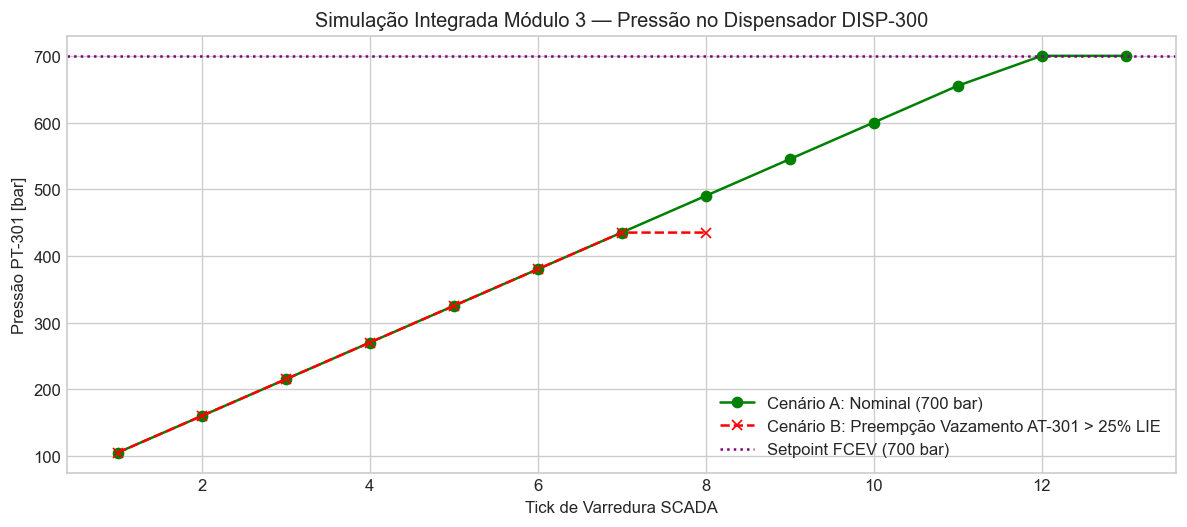

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(df_a["Tick"], df_a["PT_301_bar"], marker="o", color="green", label="Cenário A: Nominal (700 bar)")
ax.plot(df_b["Tick"], df_b["PT_301_bar"], marker="x", color="red", linestyle="--", label="Cenário B: Preempção Vazamento AT-301 > 25% LIE")
ax.axhline(700.0, color="purple", linestyle=":", label="Setpoint FCEV (700 bar)")
ax.set_title("Simulação Integrada Módulo 3 — Pressão no Dispensador DISP-300")
ax.set_xlabel("Tick de Varredura SCADA")
ax.set_ylabel("Pressão PT-301 [bar]")
ax.legend()
plt.tight_layout()
plt.show()